# LeetCode #1486: XOR Operation in an Array

https://leetcode.com/problems/xor-operation-in-an-array/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force** | $O(n)$ | $O(n)$ |
| **Optimal: XOR Scan ★** | $O(n)$ | $O(1)$ |

---

## Understanding the Methods

### Brute Force
Build the full array `nums[i] = start + 2*i` explicitly, then XOR all elements. Allocates an $O(n)$ array that is never needed again.

### Optimal: XOR Scan ★
Compute each element on the fly and XOR it into a running accumulator without storing the array. One pass, constant extra memory.

**Why this is better than Brute Force:** Skipping the array allocation keeps space at $O(1)$ with no change in time complexity; the XOR accumulation is trivially equivalent to building and then XOR-ing the array.

**Constraints:**
* 1 <= n <= 1000
* 0 <= start <= 1000
* n and start are both even

## Solutions

### C#

In [ ]:
public class Solution {
    public int XorOperation(int n, int start) {
        int result = 0;
        for (int i = 0; i < n; i++) {
            // Compute each element on the fly: nums[i] = start + 2*i
            result ^= start + 2 * i;
        }
        return result;
    }
}

### Python

In [ ]:
class Solution:
    def xorOperation(self, n: int, start: int) -> int:
        result = 0
        for i in range(n):
            # Compute each element on the fly: nums[i] = start + 2*i
            result ^= start + 2 * i
        return result

### Go

In [ ]:
func xorOperation(n int, start int) int {
    result := 0
    for i := 0; i < n; i++ {
        // Compute each element on the fly: nums[i] = start + 2*i
        result ^= start + 2*i
    }
    return result
}

### Rust

In [ ]:
impl Solution {
    pub fn xor_operation(n: i32, start: i32) -> i32 {
        let mut result = 0;
        for i in 0..n {
            // Compute each element on the fly: nums[i] = start + 2*i
            result ^= start + 2 * i;
        }
        result
    }
}

## Example Scenarios

The array $\text{nums}[i] = \text{start} + 2i$ is never built. Each element is computed from $i$ as the loop runs and folded straight into a running accumulator, so the whole problem reduces to one pass and one integer. Every element shares the parity of `start`, which means the low bit of the answer is fixed before the loop begins: it is $\text{start} \bmod 2$ when $n$ is odd and 0 when $n$ is even.

### 1. Common Case — Five Even Terms From Zero

**Input:** `n = 5`, `start = 0`

The conceptual array is $[0, 2, 4, 6, 8]$. Folding left to right: $0 \oplus 2 = 2$, $\oplus 4 = 6$, $\oplus 6 = 0$, $\oplus 8 = 8$. Notice the accumulator returns to 0 at step 4 because $6 \oplus 6 = 0$ — a value can cancel the accumulator exactly, which is why partial results are not monotone in any useful way. **Answer: 8.**

### 2. Slightly Complex — An Odd Start

**Input:** `n = 4`, `start = 3`

The array is $[3, 5, 7, 9]$, all odd. Folding: $3 \oplus 5 = 6$, $\oplus 7 = 1$, $\oplus 9 = 8$. **Answer: 8.** With $n = 4$ (even) the odd terms pair up and the low bit cancels to 0, which is why an all-odd array produces an even result.

### 3. Edge Case: Time Factor — Both Parameters at Their Maximum

**Input:** `n = 1000`, `start = 1000`

The largest input the constraints allow: 1000 iterations over the terms $1000, 1002, \ldots, 2998$. **Answer: 0** — all 1000 terms cancel out completely. The loop still performs every one of its 1000 XORs; nothing short-circuits, and 1000 iterations is the ceiling.

### 4. Edge Case: Space Factor — Maximum Length, Nothing Allocated

**Input:** `n = 1000`, `start = 0`

Terms $0, 2, \ldots, 1998$, and again everything cancels: **Answer: 0.** The point here is the allocation, not the result. The brute force materialises a 1000-element list purely to XOR it once and discard it; this version holds `result` and `i` and nothing else, so auxiliary space is $O(1)$ for any $n$. Same time complexity, 1000 fewer slots.

### 5. Almost-Impossible but Plausible — A Single Maximum Term

**Input:** `n = 1`, `start = 1000`

The shortest possible array holding the largest possible starting value: $[1000]$. One iteration gives $0 \oplus 1000 = 1000$. **Answer: 1000.** This is the input that checks the accumulator is seeded with 0 rather than with `nums[0]` and the loop then started at $i = 1$ — a common rewrite that still works here but breaks on $n = 0$, and that needs the seeding to be exactly right at $n = 1$.


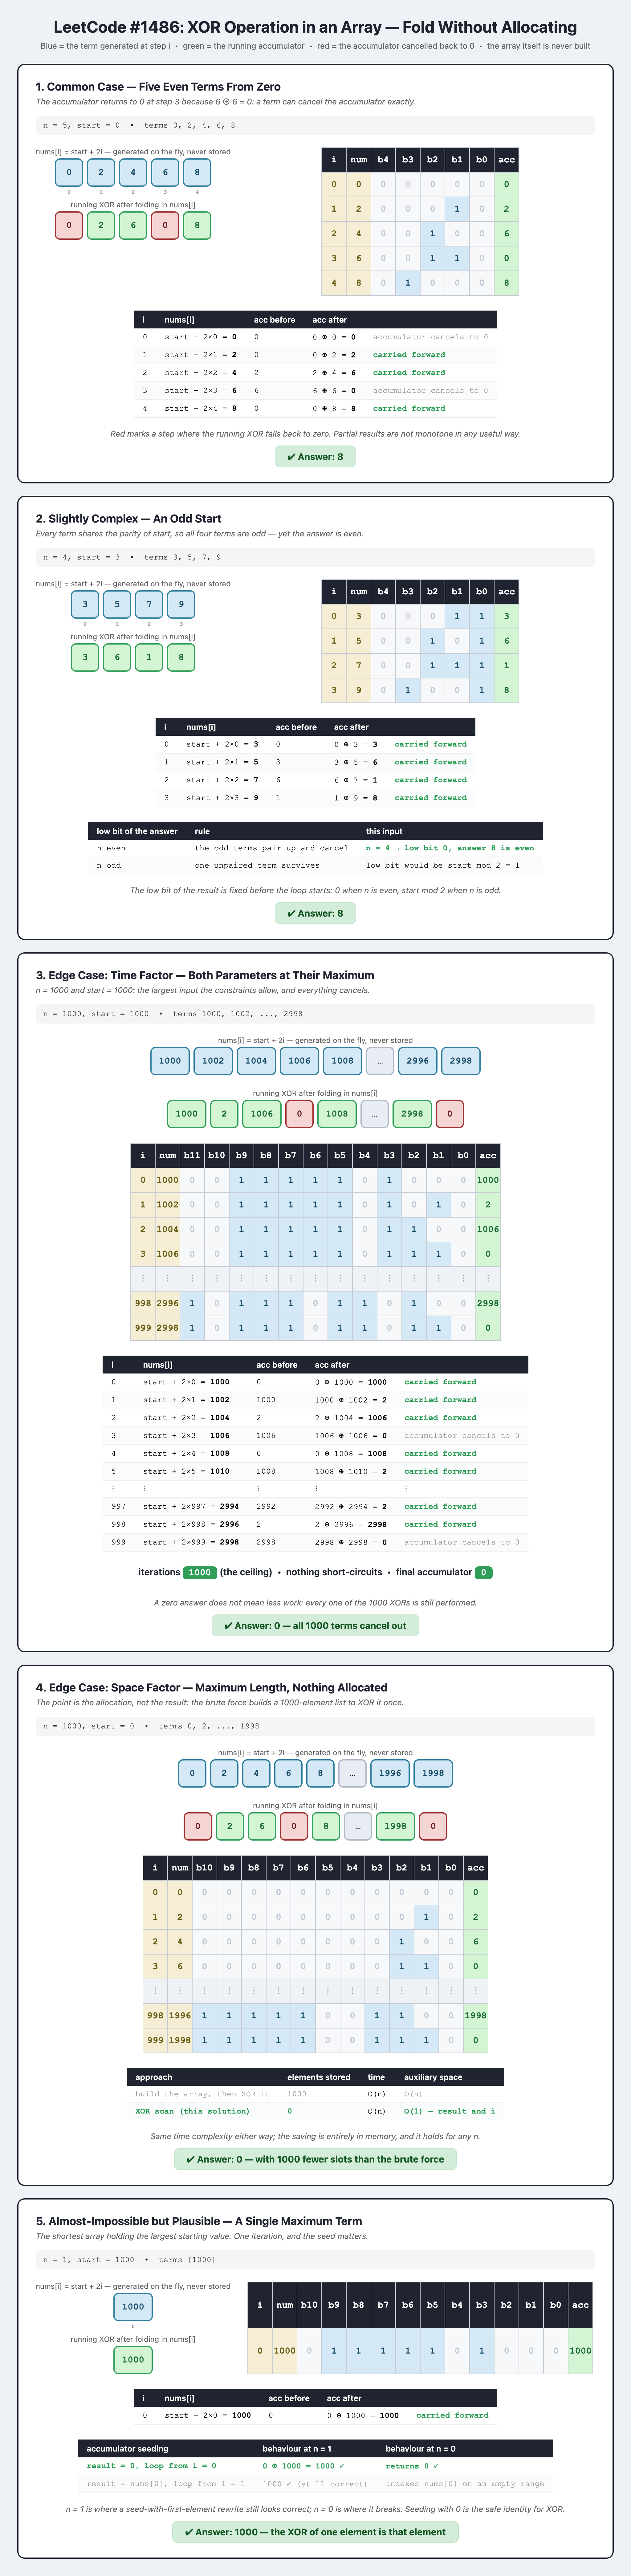